Concepts and association rules.

In [1]:
import requests, readline, sys, json
import numpy
import networkx as nx
import matplotlib as mpl
%matplotlib inline
%config InlineBacked.figure_format = 'svg'
import matplotlib.pyplot as plt
import matplotlib.cm as cmap
import seaborn
from query import *
from contexts import *
from myconcepts import *
from concepts import Definition, Context

In [3]:
d = Definition()

In [5]:
d.add_object('man', ['male'])
d.add_object('woman', ['female'])
d.add_property('adult', ['man', 'woman'])
d.add_property('child', ['boy', 'girl'])

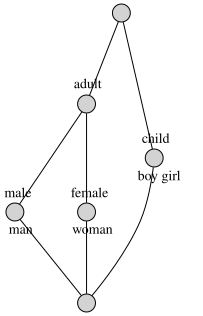

In [10]:
c = Context(*d)
c.lattice.graphviz()


In [33]:
proc_nameQ = "g.V().hasLabel('Subject').has('subjectType','SUBJECT_PROCESS').as('x').values('cid').as('pid').select('x').values('name').as('name').select('pid','name').dedup()"
nameCtxt = makeContext(getQuery(proc_nameQ),'pid','name')
nameCtxt

{'1857': {'dbus-daemon'},
 '1873': {'window-stack-br'},
 '1892': {'upstart-dbus-br'},
 '1904': {'ibus-daemon'},
 '1919': {'unity-settings-'},
 '1923': {'hud-service'},
 '1931': {'dbus-daemon'},
 '1933': {'unity-panel-ser'},
 '1937': {'at-spi2-registr'},
 '1939': {'gdbus'},
 '1958': {'gdbus'},
 '1962': {'ibus-ui-gtk3'},
 '1978': {'gdbus'},
 '1980': {'bamfdaemon'},
 '1994': {'ibus-engine-sim'},
 '1995': {'gdbus'},
 '1998': {'gdbus'},
 '2008': {'indicator-keybo'},
 '2016': {'gdbus'},
 '2122': {'compiz'},
 '2132': {'gdbus'},
 '2140': {'nautilus'},
 '2321': {'gnome-terminal'},
 '2323': {'gdbus'},
 '2328': {'bash'},
 '2694': {'bash'},
 '2710': {'audit.sh'},
 '2731': {'bash', 'sampleload'},
 '2732': {'sampleload'},
 '2733': {'sampleload'},
 '2734': {'auditlog.sh', 'bash'},
 '2735': {'auditlog.sh', 'sudo'}}

In [11]:
eventCtxt = makeContext(getQuery(proc_eventQ),'pid','type')
eventCtxt

{'1857': {'EVENT_RECVMSG', 'EVENT_SENDMSG'},
 '1873': {'EVENT_READ', 'EVENT_RECVMSG', 'EVENT_SENDMSG', 'EVENT_WRITE'},
 '1892': {'EVENT_READ', 'EVENT_RECVMSG', 'EVENT_WRITE'},
 '1904': {'EVENT_READ', 'EVENT_WRITE'},
 '1919': {'EVENT_CLOSE', 'EVENT_MMAP', 'EVENT_OPEN', 'EVENT_READ'},
 '1923': {'EVENT_READ', 'EVENT_RECVMSG', 'EVENT_WRITE'},
 '1931': {'EVENT_RECVMSG'},
 '1933': {'EVENT_READ', 'EVENT_RECVMSG', 'EVENT_WRITE'},
 '1937': {'EVENT_RECVMSG', 'EVENT_SENDMSG', 'EVENT_WRITE'},
 '1939': {'EVENT_READ', 'EVENT_RECVMSG', 'EVENT_SENDMSG', 'EVENT_WRITE'},
 '1958': {'EVENT_READ', 'EVENT_RECVMSG', 'EVENT_SENDMSG', 'EVENT_WRITE'},
 '1962': {'EVENT_READ', 'EVENT_WRITE'},
 '1978': {'EVENT_READ', 'EVENT_RECVMSG', 'EVENT_SENDMSG', 'EVENT_WRITE'},
 '1980': {'EVENT_READ', 'EVENT_RECVMSG', 'EVENT_WRITE'},
 '1994': {'EVENT_READ', 'EVENT_WRITE'},
 '1995': {'EVENT_READ', 'EVENT_RECVMSG', 'EVENT_SENDMSG', 'EVENT_WRITE'},
 '1998': {'EVENT_READ', 'EVENT_RECVMSG', 'EVENT_SENDMSG', 'EVENT_WRITE'},
 '2008'

In [30]:
def mkCtxt(context): 
    d = Definition()
    for label in context.keys():
        d.add_object(label, context[label])
    c = Context(*d)
    return c

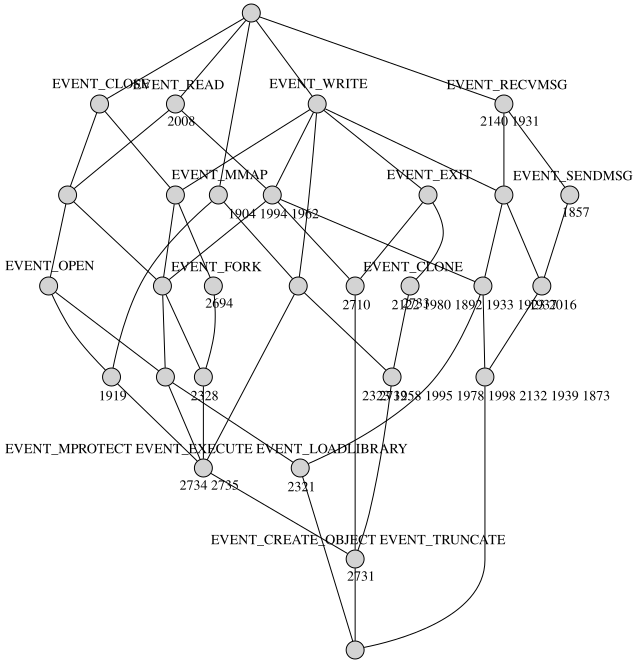

In [44]:
dot1 = mkCtxt(eventCtxt).lattice.graphviz()
dot1

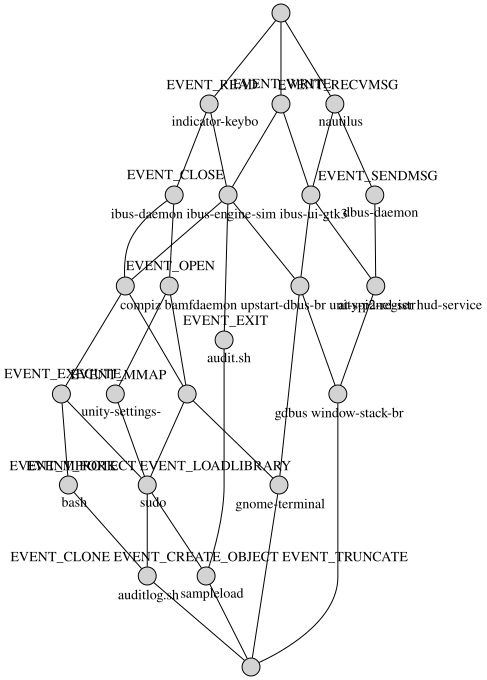

In [167]:
name_eventQ = "g.V().hasLabel('Subject').has('subjectType','SUBJECT_PROCESS').as('x').values('name').as('name').select('x').in().hasLabel('Event').as('y').values('eventType').as('type').select('name','type').dedup()"
nameEventCtxt = makeContext(getQuery(name_eventQ),'name','type')
dot4 = mkCtxt(nameEventCtxt).lattice.graphviz()
dot4.render('test-output/eventName', view=True)
dot4

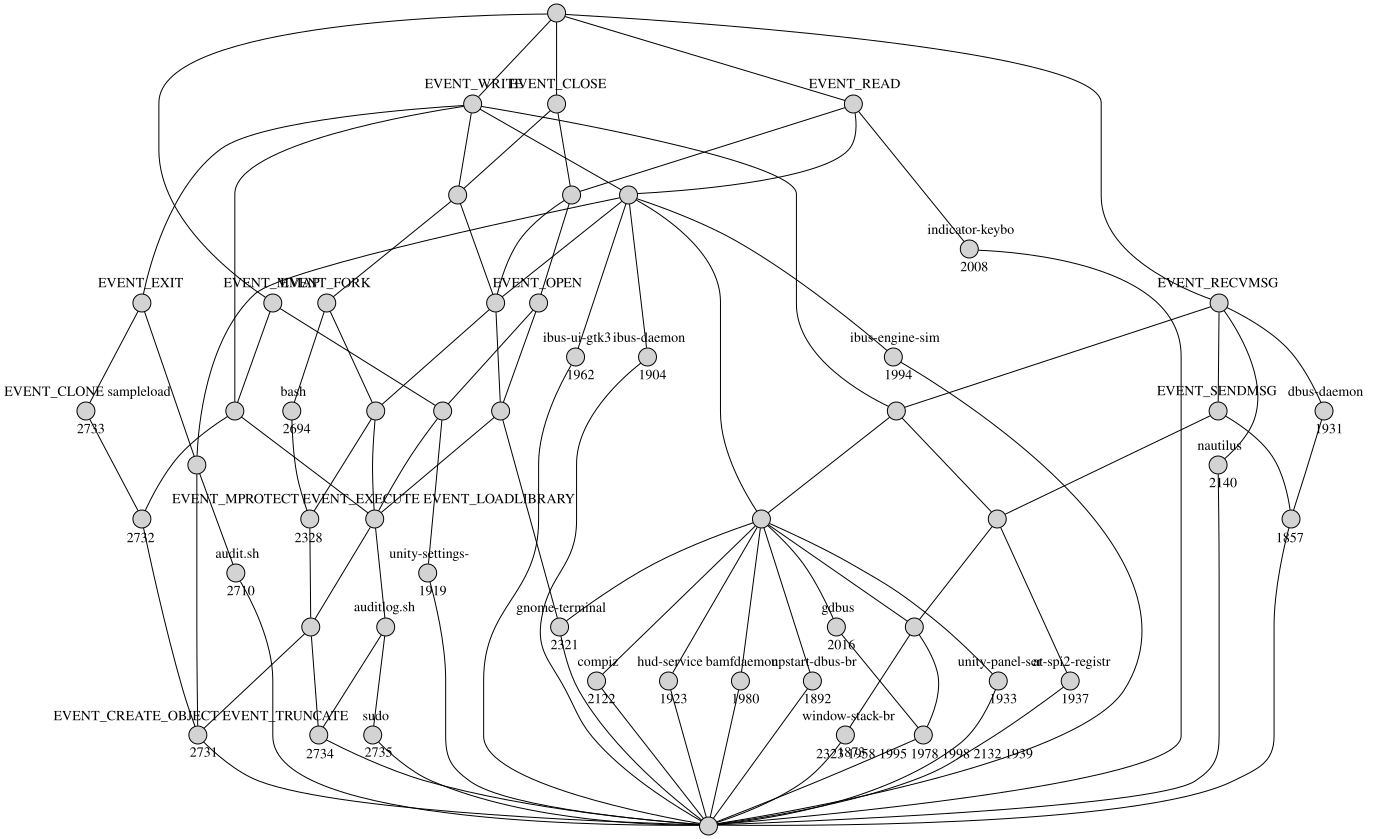

In [95]:
def combineContexts(ctx1,ctx2):
    ctx = ctx1.copy()
    for k in ctx2.keys():
        if k in ctx1.keys(): 
            ctx[k] = ctx[k] | ctx2[k]
        else:
            ctx[k] = ctx2[k]
    return ctx
context = combineContexts(eventCtxt,nameCtxt)
dot2 = mkCtxt(context).lattice.graphviz()
dot2

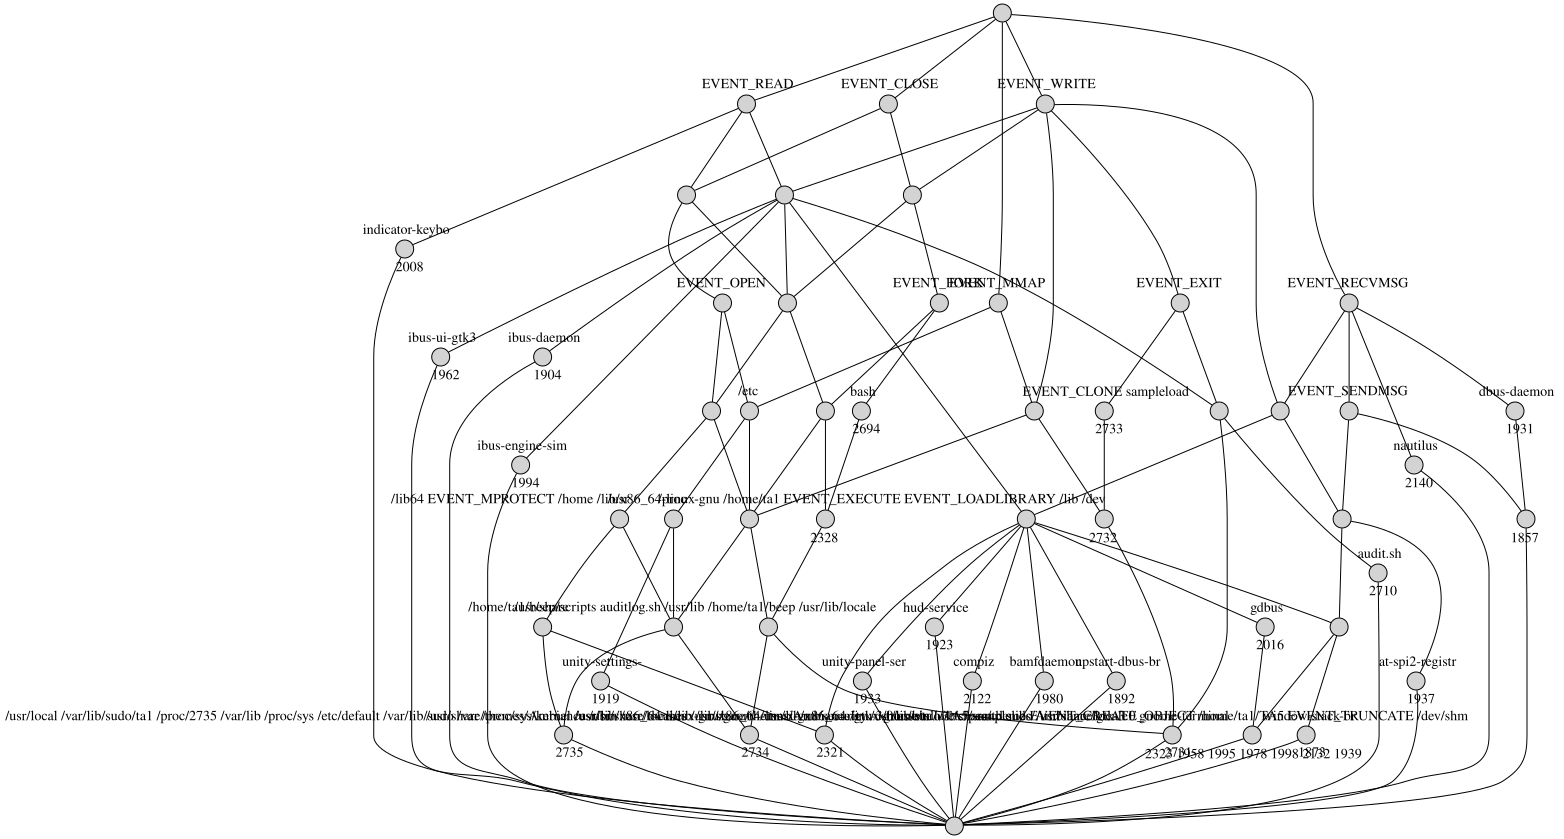

In [101]:
fileCtxt = makeContext(getQuery(proc_fileQ),'pid','file')
prefFileCtxt = {k : allprefixes(fileCtxt[k]) for k in fileCtxt.keys()}
ctx = combineContexts(prefFileCtxt,context)
mkCtxt(ctx).lattice.graphviz()


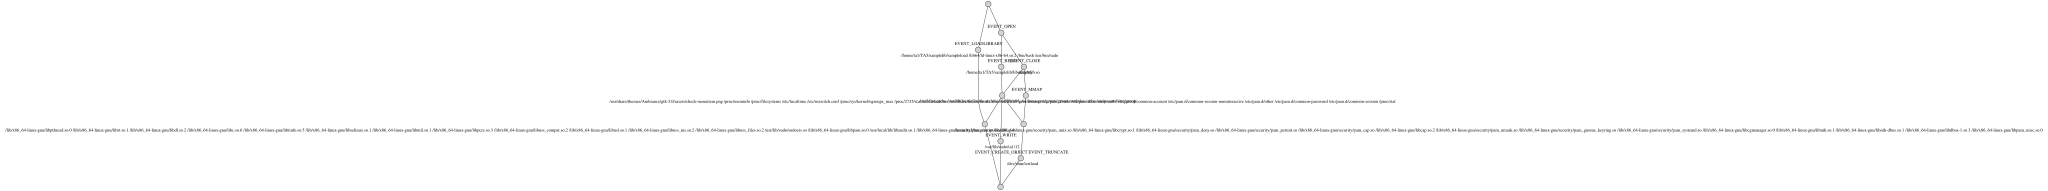

In [141]:
file_eventQ = "g.V().hasLabel('FileObject').as('z').values('path').as('file').select('z').in().hasLabel('Event').as('y').values('eventType').as('type').select('file','type')"
fileEventCtxt = makeContext(getQuery(file_eventQ),'file','type')
mkCtxt(fileEventCtxt).lattice.graphviz()


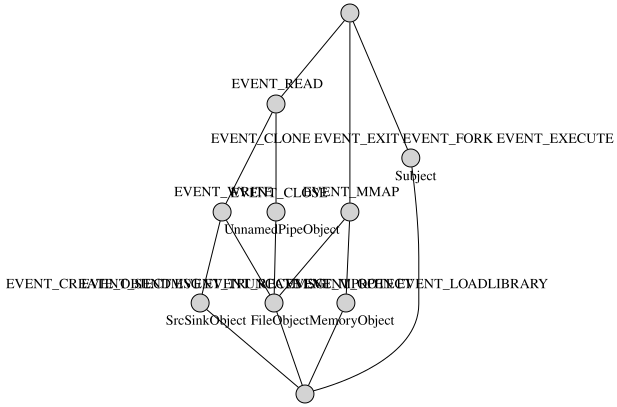

In [165]:
event_type_objectQ = "g.V().hasLabel('Event').as('y').values('eventType').as('type').select('y').out('predicateObject','predicateObject2').label().as('object').select('type','object').dedup()"
#getQuery(event_type_objectQ)
eventObjectCtxt = makeContext(getQuery(event_type_objectQ),'object','type')
dot = mkCtxt(eventObjectCtxt).lattice.graphviz()
dot.render('test-output/eventObject', view=True)
dot

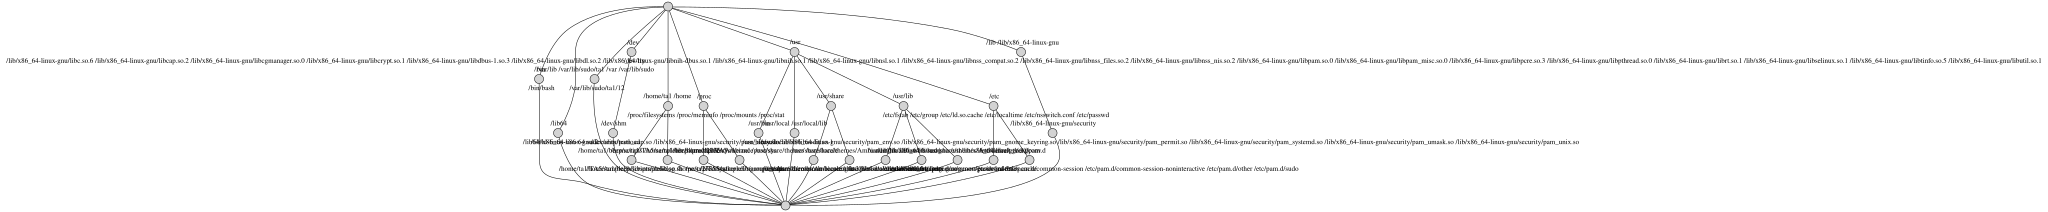

In [146]:
files = getQuery("g.V().hasLabel('FileObject').values('path').dedup().order()")
counter = 0
allFileCtxt = {}
for k in files:
    allFileCtxt[k] = prefixes(k)
mkCtxt(allFileCtxt).lattice.graphviz()



In [169]:
from datetime import datetime
def mkDate(t): 
    return datetime.fromtimestamp(int(t)/1000000000)
{mkDate(t) for t in getQuery(timestampQ)}

{datetime.datetime(2017, 4, 12, 1, 32, 33, 224000),
 datetime.datetime(2017, 4, 12, 1, 32, 33, 228000),
 datetime.datetime(2017, 4, 12, 1, 32, 33, 232000),
 datetime.datetime(2017, 4, 12, 1, 32, 33, 236000),
 datetime.datetime(2017, 4, 12, 1, 32, 33, 240000),
 datetime.datetime(2017, 4, 12, 1, 32, 33, 244000),
 datetime.datetime(2017, 4, 12, 1, 32, 33, 248000),
 datetime.datetime(2017, 4, 12, 1, 32, 33, 252000),
 datetime.datetime(2017, 4, 12, 1, 32, 33, 260000),
 datetime.datetime(2017, 4, 12, 1, 32, 33, 268000),
 datetime.datetime(2017, 4, 12, 1, 32, 33, 272000),
 datetime.datetime(2017, 4, 12, 1, 32, 33, 276000),
 datetime.datetime(2017, 4, 12, 1, 32, 33, 284000),
 datetime.datetime(2017, 4, 12, 1, 32, 33, 296000),
 datetime.datetime(2017, 4, 12, 1, 32, 33, 300000),
 datetime.datetime(2017, 4, 12, 1, 32, 33, 520000),
 datetime.datetime(2017, 4, 12, 1, 32, 33, 528000),
 datetime.datetime(2017, 4, 12, 1, 32, 33, 540000),
 datetime.datetime(2017, 4, 12, 1, 32, 33, 552000),
 datetime.da

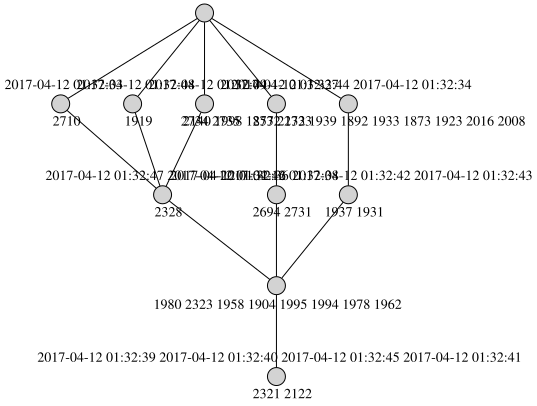

In [194]:
proc_eventTimeQ = "g.V().hasLabel('Subject').has('subjectType','SUBJECT_PROCESS').as('x').values('cid').as('pid').select('x').in().hasLabel('Event').as('y').values('timestampNanos').as('time').select('pid','time').dedup()"
def secondsApprox(dt):
    return datetime(dt.year,dt.month,dt.day,dt.hour,dt.minute,dt.second)
procTime = [{'pid':etq['pid'], 'time':str(secondsApprox(mkDate(etq['time'])))} for etq in getQuery(proc_eventTimeQ)]
procTimeCtxt = makeContext(procTime,'pid','time')
mkCtxt(procTimeCtxt).lattice.graphviz()


In [41]:
concepts = {getConcept(context,{att}) for att in getAtts(context)}
concepts

{frozenset({'EVENT_CLOSE',
            'EVENT_EXECUTE',
            'EVENT_FORK',
            'EVENT_LOADLIBRARY',
            'EVENT_MMAP',
            'EVENT_MPROTECT',
            'EVENT_OPEN',
            'EVENT_READ',
            'EVENT_WRITE',
            'auditlog.sh'}),
 frozenset({'EVENT_RECVMSG',
            'EVENT_SENDMSG',
            'EVENT_WRITE',
            'at-spi2-registr'}),
 frozenset({'EVENT_CLOSE', 'EVENT_FORK', 'EVENT_WRITE', 'bash'}),
 frozenset({'EVENT_RECVMSG', 'dbus-daemon'}),
 frozenset({'EVENT_MMAP'}),
 frozenset({'EVENT_CLOSE'}),
 frozenset({'EVENT_READ'}),
 frozenset({'EVENT_CLOSE', 'EVENT_OPEN', 'EVENT_READ'}),
 frozenset({'EVENT_CLOSE',
            'EVENT_EXECUTE',
            'EVENT_FORK',
            'EVENT_LOADLIBRARY',
            'EVENT_MMAP',
            'EVENT_MPROTECT',
            'EVENT_OPEN',
            'EVENT_READ',
            'EVENT_WRITE',
            'auditlog.sh',
            'sudo'}),
 frozenset({'EVENT_CLOSE',
            'EVENT_MMAP

In [6]:
extendConcept(context,frozenset())

{frozenset({'EVENT_RECVMSG', 'dbus-daemon'}),
 frozenset({'EVENT_READ',
            'EVENT_RECVMSG',
            'EVENT_SENDMSG',
            'EVENT_WRITE',
            'window-stack-br'}),
 frozenset({'EVENT_CLOSE'}),
 frozenset({'EVENT_CLOSE',
            'EVENT_EXECUTE',
            'EVENT_FORK',
            'EVENT_LOADLIBRARY',
            'EVENT_MMAP',
            'EVENT_MPROTECT',
            'EVENT_OPEN',
            'EVENT_READ',
            'EVENT_WRITE',
            'auditlog.sh'}),
 frozenset({'EVENT_READ', 'EVENT_RECVMSG', 'EVENT_WRITE', 'compiz'}),
 frozenset({'EVENT_READ', 'indicator-keybo'}),
 frozenset({'EVENT_READ', 'EVENT_RECVMSG', 'EVENT_WRITE', 'upstart-dbus-br'}),
 frozenset({'EVENT_CLOSE', 'EVENT_FORK', 'EVENT_WRITE'}),
 frozenset({'EVENT_CLOSE',
            'EVENT_EXECUTE',
            'EVENT_FORK',
            'EVENT_LOADLIBRARY',
            'EVENT_MMAP',
            'EVENT_MPROTECT',
            'EVENT_OPEN',
            'EVENT_READ',
            'EVENT_WRITE'

In [7]:
testContext = {'a': {'y'}, 'b': {'z'},'c':{'x','y'}}
findAllConcepts(testContext)

{frozenset(),
 frozenset({'x', 'y'}),
 frozenset({'z'}),
 frozenset({'y'}),
 frozenset({'x', 'y', 'z'})}

In [8]:
concepts = findAllConceptsWithMinSupp(context,0.05*len(context))
concepts

{frozenset(),
 frozenset({'EVENT_WRITE'}),
 frozenset({'EVENT_RECVMSG', 'EVENT_WRITE'}),
 frozenset({'EVENT_CLOSE', 'EVENT_WRITE'}),
 frozenset({'EVENT_RECVMSG', 'dbus-daemon'}),
 frozenset({'EVENT_CLOSE'}),
 frozenset({'EVENT_READ', 'EVENT_WRITE'}),
 frozenset({'EVENT_CLOSE', 'EVENT_FORK', 'EVENT_WRITE'}),
 frozenset({'EVENT_CLOSE', 'EVENT_FORK', 'EVENT_READ', 'EVENT_WRITE'}),
 frozenset({'EVENT_MMAP'}),
 frozenset({'EVENT_READ'}),
 frozenset({'EVENT_CLOSE', 'EVENT_READ'}),
 frozenset({'EVENT_CLOSE', 'EVENT_READ', 'EVENT_WRITE'}),
 frozenset({'EVENT_CLOSE',
            'EVENT_EXECUTE',
            'EVENT_FORK',
            'EVENT_LOADLIBRARY',
            'EVENT_MMAP',
            'EVENT_MPROTECT',
            'EVENT_OPEN',
            'EVENT_READ',
            'EVENT_WRITE'}),
 frozenset({'EVENT_CLOSE', 'EVENT_FORK', 'EVENT_READ', 'EVENT_WRITE', 'bash'}),
 frozenset({'EVENT_CLOSE', 'EVENT_OPEN', 'EVENT_READ'}),
 frozenset({'EVENT_CLOSE', 'EVENT_OPEN', 'EVENT_READ', 'EVENT_WRITE'}),
 

In [9]:
# naive
def successor(concepts,c1,c2):
    return c1 < c2 and {c for c in concepts if c1 < c and c < c2} == set()
def edges(concepts):
    return {(c1,c2) for c1 in concepts for c2 in concepts if successor(concepts,c1,c2)}
edges(concepts)

{(frozenset(), frozenset({'EVENT_MMAP'})),
 (frozenset(), frozenset({'EVENT_READ'})),
 (frozenset(), frozenset({'EVENT_RECVMSG'})),
 (frozenset(), frozenset({'EVENT_WRITE'})),
 (frozenset(), frozenset({'EVENT_CLOSE'})),
 (frozenset({'EVENT_READ'}), frozenset({'EVENT_READ', 'EVENT_WRITE'})),
 (frozenset({'EVENT_WRITE'}), frozenset({'EVENT_CLOSE', 'EVENT_WRITE'})),
 (frozenset({'EVENT_READ'}), frozenset({'EVENT_CLOSE', 'EVENT_READ'})),
 (frozenset({'EVENT_WRITE'}), frozenset({'EVENT_READ', 'EVENT_WRITE'})),
 (frozenset({'EVENT_READ', 'EVENT_RECVMSG', 'EVENT_WRITE', 'gdbus'}),
  frozenset({'EVENT_READ',
             'EVENT_RECVMSG',
             'EVENT_SENDMSG',
             'EVENT_WRITE',
             'gdbus'})),
 (frozenset({'EVENT_EXIT', 'EVENT_WRITE'}),
  frozenset({'EVENT_CLONE', 'EVENT_EXIT', 'EVENT_WRITE', 'sampleload'})),
 (frozenset({'EVENT_CLOSE', 'EVENT_WRITE'}),
  frozenset({'EVENT_CLOSE', 'EVENT_READ', 'EVENT_WRITE'})),
 (frozenset({'EVENT_CLOSE', 'EVENT_FORK', 'EVENT_WRITE'}

In [10]:
getSupports(context,concepts)

{frozenset(): 32,
 frozenset({'EVENT_WRITE'}): 27,
 frozenset({'EVENT_RECVMSG', 'EVENT_WRITE'}): 16,
 frozenset({'EVENT_CLOSE', 'EVENT_WRITE'}): 6,
 frozenset({'EVENT_RECVMSG', 'dbus-daemon'}): 2,
 frozenset({'EVENT_CLOSE'}): 7,
 frozenset({'EVENT_READ', 'EVENT_WRITE'}): 23,
 frozenset({'EVENT_CLOSE', 'EVENT_FORK', 'EVENT_WRITE'}): 5,
 frozenset({'EVENT_CLOSE', 'EVENT_FORK', 'EVENT_READ', 'EVENT_WRITE'}): 4,
 frozenset({'EVENT_MMAP'}): 5,
 frozenset({'EVENT_READ'}): 25,
 frozenset({'EVENT_CLOSE', 'EVENT_READ'}): 6,
 frozenset({'EVENT_CLOSE', 'EVENT_READ', 'EVENT_WRITE'}): 5,
 frozenset({'EVENT_CLOSE',
            'EVENT_EXECUTE',
            'EVENT_FORK',
            'EVENT_LOADLIBRARY',
            'EVENT_MMAP',
            'EVENT_MPROTECT',
            'EVENT_OPEN',
            'EVENT_READ',
            'EVENT_WRITE'}): 3,
 frozenset({'EVENT_CLOSE',
            'EVENT_FORK',
            'EVENT_READ',
            'EVENT_WRITE',
            'bash'}): 3,
 frozenset({'EVENT_CLOSE', 'EVEN

In [11]:
def getScaledSupports(context,concepts):
    supps = getSupports(context,concepts)
    n = len(context)
    return {k : supps[k]/n for k in supps.keys()}
getScaledSupports(context,concepts)

{frozenset(): 1.0,
 frozenset({'EVENT_WRITE'}): 0.84375,
 frozenset({'EVENT_RECVMSG', 'EVENT_WRITE'}): 0.5,
 frozenset({'EVENT_CLOSE', 'EVENT_WRITE'}): 0.1875,
 frozenset({'EVENT_RECVMSG', 'dbus-daemon'}): 0.0625,
 frozenset({'EVENT_CLOSE'}): 0.21875,
 frozenset({'EVENT_READ', 'EVENT_WRITE'}): 0.71875,
 frozenset({'EVENT_CLOSE', 'EVENT_FORK', 'EVENT_WRITE'}): 0.15625,
 frozenset({'EVENT_CLOSE', 'EVENT_FORK', 'EVENT_READ', 'EVENT_WRITE'}): 0.125,
 frozenset({'EVENT_MMAP'}): 0.15625,
 frozenset({'EVENT_READ'}): 0.78125,
 frozenset({'EVENT_CLOSE', 'EVENT_READ'}): 0.1875,
 frozenset({'EVENT_CLOSE', 'EVENT_READ', 'EVENT_WRITE'}): 0.15625,
 frozenset({'EVENT_CLOSE',
            'EVENT_EXECUTE',
            'EVENT_FORK',
            'EVENT_LOADLIBRARY',
            'EVENT_MMAP',
            'EVENT_MPROTECT',
            'EVENT_OPEN',
            'EVENT_READ',
            'EVENT_WRITE'}): 0.09375,
 frozenset({'EVENT_CLOSE',
            'EVENT_FORK',
            'EVENT_READ',
            'EVENT

In [12]:
def getConfidence(context,concepts,minconf):
    supports = getSupports(context,concepts)
    edg = edges(concepts)
    return {(e[0],e[1]-e[0]): supports[e[1]]/supports[e[0]] for e in edg if supports[e[0]] > 0 and supports[e[1]]/supports[e[0]] > minconf}
rules = getConfidence(context,concepts,0.5)

In [13]:
def violations(s,rules):
    ent = 0
    for e in rules.keys():
        if e[0] <= s and not(e[1] <= s):
            ent = ent - numpy.log2(1-rules[e])
    return ent
violations({'EVENT_MMAP','EVENT_READ'},rules)

12.265344566520998

In [14]:
def allViolations(context,rules):
    return {k:violations(context[k],rules) for k in context.keys()}
vios = allViolations(context,rules)
def snd(x): return x[1]
sorted(vios.items(),key=snd,reverse=True)

[('1919', 19.657661989299758),
 ('2694', 17.256794263157065),
 ('2321', 13.698537627541377),
 ('2328', 12.610431217771767),
 ('1937', 12.117457581548177),
 ('2732', 11.864476840378305),
 ('1857', 10.855610090664825),
 ('2735', 10.025468717050613),
 ('2733', 9.1275112462120997),
 ('1931', 8.611684507778735),
 ('2140', 8.611684507778735),
 ('2008', 7.6214883767462709),
 ('2016', 6.3701832634945834),
 ('2710', 6.1185781214420922),
 ('2731', 5.7035406221632483),
 ('1892', 4.4697189370454975),
 ('1923', 4.4697189370454975),
 ('1980', 4.4697189370454975),
 ('1933', 4.4697189370454975),
 ('2122', 4.4697189370454975),
 ('2734', 4.1185781214420913),
 ('1962', 4.1185781214420913),
 ('1904', 4.1185781214420913),
 ('1994', 4.1185781214420913),
 ('1873', 4.0995356735509141),
 ('1978', 0),
 ('1958', 0),
 ('1939', 0),
 ('2132', 0),
 ('1998', 0),
 ('1995', 0),
 ('2323', 0)]

TODO: Find 100% confidence rules, and infrequent combinations, as follows.  Consider all pairs of concepts X, Y.  Compute Z = (X U Y)'', the closure of the union of X and Y.  If Z - X U Y is nonempty and has large support, generate a 100% confidence rule X U Y -> Z.  (In principle could do this for all subsets of concepts but could be expensive.)  

To find infrequent combinations, look for X and Y such that Z = (X U Y)'' has small/no support.  Then X # Y is an infrequent combination rule (i.e. X U Y -> false)

In [15]:
def exactRules(context,concepts): 
    rules = set()
    for x in concepts:
        for y in concepts:
            xy = x | y
            z = getConcept(context,xy)
            diff = z - xy
            if z in concepts and diff != set():
                rules = rules | {(xy,diff)}
    return rules
exactRules(context,concepts)

{(frozenset({'EVENT_CLOSE', 'EVENT_MMAP'}),
  frozenset({'EVENT_OPEN', 'EVENT_READ'})),
 (frozenset({'EVENT_CLOSE', 'EVENT_MMAP', 'EVENT_WRITE'}),
  frozenset({'EVENT_EXECUTE',
             'EVENT_FORK',
             'EVENT_LOADLIBRARY',
             'EVENT_MPROTECT',
             'EVENT_OPEN',
             'EVENT_READ'})),
 (frozenset({'EVENT_MMAP', 'EVENT_READ'}),
  frozenset({'EVENT_CLOSE', 'EVENT_OPEN'})),
 (frozenset({'EVENT_MMAP', 'EVENT_READ', 'EVENT_WRITE'}),
  frozenset({'EVENT_CLOSE',
             'EVENT_EXECUTE',
             'EVENT_FORK',
             'EVENT_LOADLIBRARY',
             'EVENT_MPROTECT',
             'EVENT_OPEN'})),
 (frozenset({'EVENT_CLOSE', 'EVENT_MMAP', 'EVENT_READ'}),
  frozenset({'EVENT_OPEN'})),
 (frozenset({'EVENT_CLOSE', 'EVENT_MMAP', 'EVENT_READ', 'EVENT_WRITE'}),
  frozenset({'EVENT_EXECUTE',
             'EVENT_FORK',
             'EVENT_LOADLIBRARY',
             'EVENT_MPROTECT',
             'EVENT_OPEN'})),
 (frozenset({'EVENT_CLOSE', 'EVENT_

In [16]:
def disjointRuleImplied(r1,r2):
    (x1,y1) = r1
    (x2,y2) = r2
    return (x1 <= x2 and y1 <= y2) or (x1 <= y2 and y1 <= x2)
def disjointRuleRedundant(rules,r):
    for rule in rules:
        if disjointRuleImplied(rule,r):
            return True
    return False
disjointRuleImplied(({'a'},{'d'}),({'a','b'},{'c','d'}))


True

In [24]:
def updateRules(rules,r):
    return {rule for rule in rules if not disjointRuleImplied(r,rule)} | {r}
def disjointRules(context,concepts): 
    rules = set()
    for x in concepts:
        for y in concepts:
            if not(disjointRuleRedundant(rules,(x,y))):
                z = getConcept(context,x|y)
                if not(z in concepts):
                    rules = updateRules(rules,(x,y))
    return rules


drules = disjointRules(context,concepts)
drules

{(frozenset({'EVENT_EXIT', 'EVENT_WRITE'}), frozenset({'EVENT_RECVMSG'})),
 (frozenset({'EVENT_RECVMSG', 'dbus-daemon'}), frozenset({'EVENT_READ'})),
 (frozenset({'EVENT_CLONE', 'EVENT_EXIT', 'EVENT_WRITE', 'sampleload'}),
  frozenset({'EVENT_READ'})),
 (frozenset({'EVENT_RECVMSG', 'dbus-daemon'}),
  frozenset({'EVENT_RECVMSG', 'EVENT_SENDMSG'})),
 (frozenset({'EVENT_MMAP'}),
  frozenset({'EVENT_EXIT', 'EVENT_READ', 'EVENT_WRITE'})),
 (frozenset({'EVENT_MMAP'}), frozenset({'EVENT_RECVMSG'})),
 (frozenset({'EVENT_CLOSE'}), frozenset({'EVENT_EXIT', 'EVENT_WRITE'})),
 (frozenset({'EVENT_CLOSE'}), frozenset({'EVENT_RECVMSG'})),
 (frozenset({'EVENT_CLOSE',
             'EVENT_EXECUTE',
             'EVENT_FORK',
             'EVENT_LOADLIBRARY',
             'EVENT_MMAP',
             'EVENT_MPROTECT',
             'EVENT_OPEN',
             'EVENT_READ',
             'EVENT_WRITE',
             'auditlog.sh'}),
  frozenset({'EVENT_CLOSE', 'EVENT_FORK', 'EVENT_WRITE', 'bash'})),
 (frozenset

In [25]:
def druleViolations(s,drules):
    count = 0
    for rule in drules:
        if rule[0] <= s and rule[1] <= s:
            count = count + 1
    return count
def druleViolationsCtxt(context,drules):
    return {label:druleViolations(context[label],drules) for label in context.keys()}
druleViolationsCtxt(context,drules)

{'1857': 1,
 '1873': 0,
 '1892': 0,
 '1904': 0,
 '1919': 0,
 '1923': 0,
 '1931': 0,
 '1933': 0,
 '1937': 0,
 '1939': 0,
 '1958': 0,
 '1962': 0,
 '1978': 0,
 '1980': 0,
 '1994': 0,
 '1995': 0,
 '1998': 0,
 '2008': 0,
 '2016': 0,
 '2122': 0,
 '2132': 0,
 '2140': 0,
 '2321': 1,
 '2323': 0,
 '2328': 0,
 '2694': 0,
 '2710': 0,
 '2731': 3,
 '2732': 0,
 '2733': 0,
 '2734': 1,
 '2735': 0}

In [28]:
def importance(context,concepts):
    return {concept: len(concept) * getSupport(context,concept) for concept in concepts}
importances = importance(context,concepts)
sorted(importances.items(),key=snd,reverse=True)

[(frozenset({'EVENT_CLONE', 'EVENT_EXIT', 'EVENT_WRITE'}), 339),
 (frozenset({'EVENT_CLONE', 'EVENT_EXIT'}), 316),
 (frozenset({'EVENT_EXIT', 'EVENT_WRITE'}), 316),
 (frozenset({'EVENT_CLOSE', 'EVENT_MMAP', 'EVENT_OPEN', 'EVENT_READ'}), 308),
 (frozenset({'EVENT_CLONE', 'EVENT_EXIT', 'EVENT_UNIT'}), 306),
 (frozenset({'EVENT_READ', 'EVENT_WRITE'}), 302),
 (frozenset({'EVENT_CLONE', 'EVENT_EXIT', 'firefox'}), 291),
 (frozenset({'EVENT_CLONE', 'EVENT_EXIT', 'EVENT_UNIT', 'EVENT_WRITE'}), 284),
 (frozenset({'EVENT_CLOSE', 'EVENT_OPEN', 'EVENT_READ', 'EVENT_WRITE'}), 272),
 (frozenset({'EVENT_CLOSE', 'EVENT_MMAP', 'EVENT_READ', 'EVENT_WRITE'}), 268),
 (frozenset({'EVENT_MMAP', 'EVENT_OPEN', 'EVENT_READ', 'EVENT_WRITE'}), 264),
 (frozenset({'EVENT_CLONE', 'EVENT_WRITE'}), 262),
 (frozenset({'EVENT_WRITE'}), 253),
 (frozenset({'EVENT_CLOSE', 'EVENT_OPEN', 'EVENT_READ'}), 240),
 (frozenset({'EVENT_READ', 'EVENT_RECVMSG', 'EVENT_WRITE'}), 240),
 (frozenset({'EVENT_CLOSE', 'EVENT_MMAP', 'EVENT_

Remove all attribute subsets that are covered by a concept, and count how many attributes are left over.

In [31]:
def abnormality(concepts,attrs):
    matches = {concept for concept in concepts if concept <= attrs}
    for match in matches:
        attrs = attrs - match
    return len(attrs)
abnormals = {k: abnormality(concepts,context[k]) for k in context.keys()}
sorted(abnormals.items(),key=snd,reverse=True)

[('2952', 11),
 ('3124', 8),
 ('2900', 7),
 ('3051', 7),
 ('3145', 7),
 ('2915', 7),
 ('2911', 7),
 ('2901', 7),
 ('3118', 7),
 ('3131', 7),
 ('3146', 6),
 ('2933', 6),
 ('2936', 6),
 ('3136', 5),
 ('2917', 5),
 ('3116', 5),
 ('2951', 5),
 ('3141', 5),
 ('2939', 5),
 ('3134', 5),
 ('2948', 5),
 ('2926', 5),
 ('2920', 5),
 ('3139', 5),
 ('2931', 5),
 ('3137', 5),
 ('2922', 5),
 ('3144', 5),
 ('2940', 5),
 ('2924', 5),
 ('2942', 5),
 ('2947', 5),
 ('2946', 5),
 ('2935', 5),
 ('2943', 5),
 ('2937', 5),
 ('3143', 5),
 ('2934', 5),
 ('3132', 5),
 ('2919', 5),
 ('2899', 5),
 ('3117', 5),
 ('2941', 5),
 ('2938', 5),
 ('1921', 4),
 ('2976', 4),
 ('2075', 4),
 ('2874', 3),
 ('3054', 3),
 ('3015', 3),
 ('3125', 3),
 ('3127', 3),
 ('2867', 3),
 ('1751', 2),
 ('1642', 2),
 ('2958', 2),
 ('2914', 2),
 ('2869', 2),
 ('2913', 2),
 ('1854', 2),
 ('3129', 2),
 ('3026', 2),
 ('1674', 2),
 ('2955', 2),
 ('1767', 2),
 ('3126', 2),
 ('2912', 2),
 ('3073', 2),
 ('3128', 2),
 ('1848', 2),
 ('3105', 1),
 ('16

In [96]:
{concept for concept in concepts if getSupport(context,concept) > 12}

{frozenset(),
 frozenset({'EVENT_WRITE'}),
 frozenset({'EVENT_READ'}),
 frozenset({'EVENT_READ', 'EVENT_WRITE'}),
 frozenset({'EVENT_RECVMSG'}),
 frozenset({'EVENT_RECVMSG', 'EVENT_WRITE'}),
 frozenset({'EVENT_READ', 'EVENT_RECVMSG', 'EVENT_WRITE'})}

In [97]:
testContext = {'a': {'y'}, 'f':{'x'},'b': {'z'},'c':{'x','y'},'d':{'y'},'e':{'y'}}
findAllConceptsWithMinSupp(testContext,2)

{frozenset(), frozenset({'x'}), frozenset({'y'})}

In [98]:
findAllConceptsWithMinSupp(context,20)

{frozenset(),
 frozenset({'EVENT_READ'}),
 frozenset({'EVENT_WRITE'}),
 frozenset({'EVENT_READ', 'EVENT_WRITE'})}

In [99]:
context = makeContext(getQuery(proc_child_nameQ),'parent','child')


In [100]:
getSupports(context,findAllConceptsWithMinSupp(context,0.1*len(context)))

{frozenset(): 6,
 frozenset({'auditlog.sh'}): 2,
 frozenset({'bash'}): 3,
 frozenset({'auditlog.sh', 'bash'}): 1,
 frozenset({'bash', 'sampleload'}): 1,
 frozenset({'gdbus', 'ibus-engine-sim', 'ibus-ui-gtk3'}): 1,
 frozenset({'auditlog.sh', 'sudo'}): 1,
 frozenset({'sampleload'}): 2}

In [ ]:
context = makeContext(getQuery(proc_fileQ),'pid','file')

In [ ]:
getSupports(context,findAllConceptsWithMinSupp(context,0.2*len(context)))

In [38]:
context2 = {k:allprefixes(context[k]) for k in context.keys()}

In [39]:
getSupports(context2,findAllConceptsWithMinSupp(context2,0.1*len(context2)))

{frozenset(): 5,
 frozenset({'/etc'}): 4,
 frozenset({'/usr', '/usr/share'}): 2,
 frozenset({'/dev',
            '/etc',
            '/home',
            '/home/ta1',
            '/lib',
            '/lib/x86_64-linux-gnu',
            '/lib64'}): 3,
 frozenset({'/dev',
            '/dev/shm',
            '/etc',
            '/home',
            '/home/ta1',
            '/home/ta1/TA5',
            '/home/ta1/TA5/samplelib',
            '/lib',
            '/lib/x86_64-linux-gnu',
            '/lib64'}): 1,
 frozenset({'/etc', '/proc'}): 3,
 frozenset({'/usr'}): 3,
 frozenset({'/dev',
            '/etc',
            '/etc/default',
            '/etc/pam.d',
            '/home',
            '/home/ta1',
            '/home/ta1/beep',
            '/home/ta1/beep/scripts',
            '/lib',
            '/lib/x86_64-linux-gnu',
            '/lib/x86_64-linux-gnu/security',
            '/lib64',
            '/proc',
            '/proc/2735',
            '/proc/sys',
            '/proc/sys/

In [40]:
bagofwords(" a b cde f ",' ')

{'a', 'b', 'cde', 'f'}

In [41]:
allbagofwords({'a b cde f', ' gh i jkl '}, ' ')

{'a', 'b', 'cde', 'f', 'gh', 'i', 'jkl'}

In [43]:
context3 = {k:allbagofwords(context[k],'/') for k in context.keys()}

In [45]:
getSupports(context3,findAllConceptsWithMinSupp(context3,0.1*len(context3)))

{frozenset(): 5,
 frozenset({'etc'}): 4,
 frozenset({'etc', 'proc'}): 3,
 frozenset({'etc', 'fstab', 'mounts', 'proc'}): 1,
 frozenset({'dev',
            'etc',
            'home',
            'ld-linux-x86-64.so.2',
            'ld.so.cache',
            'lib',
            'lib64',
            'libc.so.6',
            'libdl.so.2',
            'ta1',
            'x86_64-linux-gnu'}): 3,
 frozenset({'usr'}): 3,
 frozenset({'auditlog.sh',
            'beep',
            'bin',
            'dev',
            'etc',
            'home',
            'ld-linux-x86-64.so.2',
            'ld.so.cache',
            'lib',
            'lib64',
            'libc.so.6',
            'libdl.so.2',
            'locale',
            'locale-archive',
            'proc',
            'scripts',
            'ta1',
            'tty',
            'usr',
            'x86_64-linux-gnu'}): 2,
 frozenset({'auditlog.sh',
            'bash',
            'beep',
            'bin',
            'dev',
            

In [46]:
concepts3 = findAllConceptsWithMinSupp(context3,0.1*len(context3))
getConfidences(context3,concepts3)

NameError: name 'getConfidences' is not defined